# Football Field (Valuation Summary)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Floating horizontal bars show the implied value-per-share range from each valuation method (trading range, analyst targets, comparable companies, precedent deals, DCF, LBO) against the current share price. It is the standard investment-banking summary of 'what is this company worth?'.

## When to use

- Summarise several valuation approaches on one common scale (value per share or EV)
- Support M&A, fairness-opinion or equity-research discussions
- Show where a proposed offer price sits relative to each method

## Avoid when

- The ranges come from inconsistent assumptions (net debt, share count or date); reconcile first
- Only one method is available (show its sensitivity table instead)

## Alternatives

- DCF sensitivity table
- Dot plot of point estimates with ranges

## Design tips

- Group methods by family (market, relative, intrinsic) with consistent colors
- Label the low and high values at each bar end
- Draw the current price (and any offer price) as vertical reference lines across all bars
- State the key assumption behind each range in its label

## Example

A fictional company with 250M shares and $1.8bn net debt; ranges computed from multiples, a five-year DCF and a simple LBO (illustrative).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
shares, net_debt, price_now = 250.0, 1800.0, 38.50          # millions / $m / $
ebitda_ltm, ebitda_ntm = 900.0, 980.0
fcf = np.array([600, 650, 700, 740, 780.0])                   # 5-year free cash flow forecast ($m)
ebitda_y5 = 1150.0


def per_share(ev):
    return (ev - net_debt) / shares


def dcf_ev(wacc, g=None, exit_multiple=None):
    t = np.arange(1, len(fcf) + 1)
    pv = (fcf / (1 + wacc) ** t).sum()
    tv = fcf[-1] * (1 + g) / (wacc - g) if g is not None else exit_multiple * ebitda_y5
    return pv + tv / (1 + wacc) ** len(fcf)


def lbo_entry_ev(irr, leverage=6.0, exit_multiple=10.0, debt_paydown=2000.0):
    debt0 = leverage * ebitda_ltm
    exit_equity = exit_multiple * ebitda_y5 - (debt0 - debt_paydown)
    return exit_equity / (1 + irr) ** 5 + debt0


rows = [
    ("52-week trading range", "Market", 31.2, 44.8),
    ("Analyst price targets", "Market", 36.0, 52.0),
    ("Trading comps: 10–13x NTM EBITDA", "Relative", per_share(10 * ebitda_ntm), per_share(13 * ebitda_ntm)),
    ("Precedent deals: 12–15x LTM EBITDA", "Relative", per_share(12 * ebitda_ltm), per_share(15 * ebitda_ltm)),
    ("DCF: WACC 8–9.5%, growth 1.5–2.5%", "Intrinsic", per_share(dcf_ev(0.095, g=0.015)), per_share(dcf_ev(0.08, g=0.025))),
    ("DCF: exit multiple 9–11x", "Intrinsic", per_share(dcf_ev(0.0875, exit_multiple=9)), per_share(dcf_ev(0.0875, exit_multiple=11))),
    ("LBO: 20–25% target IRR", "Intrinsic", per_share(lbo_entry_ev(0.25)), per_share(lbo_entry_ev(0.20))),
]
df = pd.DataFrame(rows, columns=["method", "family", "low", "high"]).round(2)
df

,method,family,low,high
0,52-week trading range,Market,31.20,44.80
1,Analyst price targets,Market,36.00,52.00
2,Trading comps: 10–13x NTM EBITDA,Relative,32.00,43.76
3,Precedent deals: 12–15x LTM EBITDA,Relative,36.00,46.80
4,"DCF: WACC 8–9.5%, growth 1.5–2.5%",Intrinsic,28.48,43.35
5,DCF: exit multiple 9–11x,Intrinsic,30.77,36.82
6,LBO: 20–25% target IRR,Intrinsic,25.02,27.42


### Plot

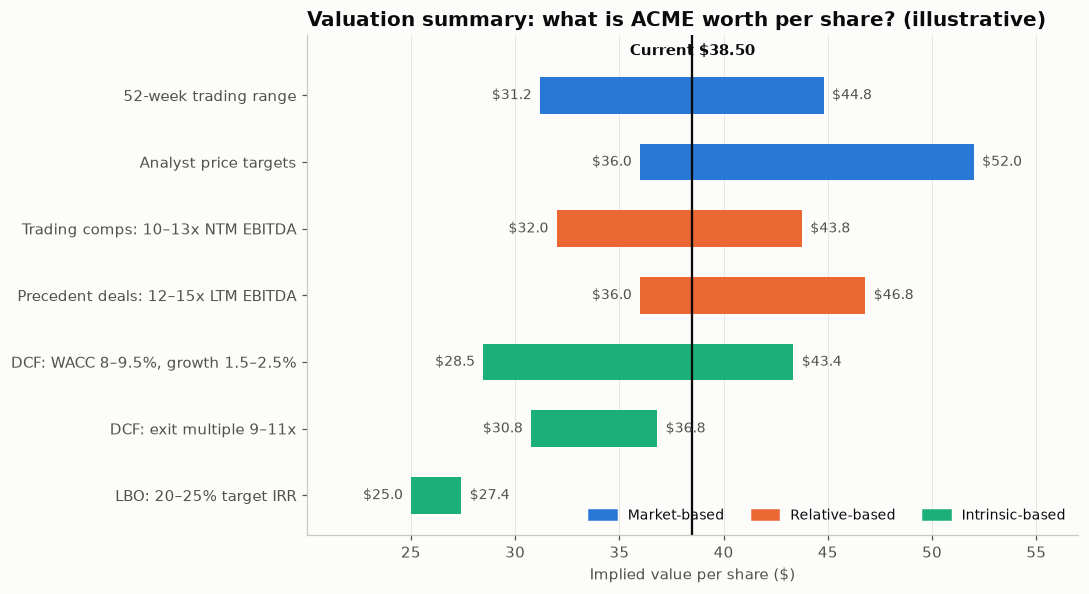

In [3]:
family_color = {"Market": PALETTE[0], "Relative": PALETTE[1], "Intrinsic": PALETTE[2]}
fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(df))[::-1]
for yi, row in zip(y, df.itertuples()):
    ax.barh(yi, row.high - row.low, left=row.low, height=0.55, color=family_color[row.family])
    ax.text(row.low - 0.4, yi, f"${row.low:.1f}", ha="right", va="center", fontsize=9, color="#52514e")
    ax.text(row.high + 0.4, yi, f"${row.high:.1f}", ha="left", va="center", fontsize=9, color="#52514e")
ax.axvline(price_now, color="#0b0b0b", linewidth=1.5)
ax.text(price_now, y[0] + 0.55, f"Current ${price_now:.2f}", ha="center", va="bottom", fontsize=9.5,
        fontweight="bold")
ax.set_yticks(y, df["method"])
ax.set_xlim(df["low"].min() - 5, df["high"].max() + 5)
ax.set_ylim(-0.6, len(df) - 0.1)
ax.set_xlabel("Implied value per share ($)")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in family_color.values()]
ax.legend(handles, [f"{k}-based" for k in family_color], loc="lower right", ncol=3, fontsize=9)
ax.set_title("Valuation summary: what is ACME worth per share? (illustrative)")
fig.tight_layout()
plt.show()

## How to read it

Each bar is the range of value per share from one method. Most bars span the current $38.50 price. The LBO range sits lowest, as it usually does, because it is the price a financial buyer could pay and still earn a 20–25% return.

---
Standalone script: [`football_field_valuation.py`](football_field_valuation.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)